In [ ]:
!pip install -q fiftyone pycocotools torchmetrics


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 148.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.2/983.2 kB 70.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.6/112.6 kB 12.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.6/61.6 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.4/112.4 kB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.8/74.8 kB 7.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 156.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 101.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 313.3/313.3 kB 29.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 934.3/934.3 kB 68.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.8/43.8 kB 4.3 MB/s et

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image, ImageDraw
import fiftyone as fo
import fiftyone.zoo as foz
import numpy as np
import os, time, random
import matplotlib.pyplot as plt
from tqdm import tqdm
from google.colab import drive


/usr/local/lib/python3.12/dist-packages/glob2/fnmatch.py:141: SyntaxWarning: invalid escape sequence '\Z'
  return '(?ms)' + res + '\Z'


In [ ]:
drive.mount("/content/drive")


Mounted at /content/drive


In [ ]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
IMG_SIZE = 448
S, B = 7, 2
CLASSES = ["person", "car", "dog", "cat", "bicycle"]
NUM_CLASSES = len(CLASSES)

CLASS2IDX = {c:i for i,c in enumerate(CLASSES)}
IDX2CLASS = {i:c for c,i in CLASS2IDX.items()}


In [ ]:
dataset = foz.load_zoo_dataset(
    "coco-2017",
    split="train",
    classes=CLASSES,
    max_samples=500,
    # dataset_dir="/content/drive/MyDrive/fiftyone_datasets/coco",
    label_types=["detections"],
    shuffle=True,
)

dataset.persistent = True
dataset.save()
print("Dataset samples:", len(dataset))


INFO:fiftyone.zoo.datasets:Downloading split 'train' to '/root/fiftyone/coco-2017/train' if necessary


INFO:fiftyone.utils.coco:Downloading annotations to '/root/fiftyone/coco-2017/tmp-download/annotations_trainval2017.zip'


 100% |██████|    1.9Gb/1.9Gb [16.8s elapsed, 0s remaining, 127.5Mb/s]      


INFO:eta.core.utils: 100% |██████|    1.9Gb/1.9Gb [16.8s elapsed, 0s remaining, 127.5Mb/s]      


Extracting annotations to '/root/fiftyone/coco-2017/raw/instances_train2017.json'


INFO:fiftyone.utils.coco:Extracting annotations to '/root/fiftyone/coco-2017/raw/instances_train2017.json'


... (10 outputs left out)

INFO:eta.core.utils: 100% |█████████████████| 500/500 [3.1s elapsed, 0s remaining, 175.7 samples/s]      


Dataset 'coco-2017-train-500' created


INFO:fiftyone.zoo.datasets:Dataset 'coco-2017-train-500' created


Dataset samples: 500


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 139MB/s]
Epoch 1: 100%|██████████| 125/125 [02:49<00:00,  1.35s/it, loss=1.15]


Epoch 1 | Avg Loss: 0.6855


Epoch 2: 100%|██████████| 125/125 [02:51<00:00,  1.37s/it, loss=0.295]


Epoch 2 | Avg Loss: 0.6111


Epoch 3: 100%|██████████| 125/125 [02:50<00:00,  1.37s/it, loss=0.926]


... (21 outputs left out)

Epoch 14: 100%|██████████| 125/125 [02:52<00:00,  1.38s/it, loss=0.709]


Epoch 14 | Avg Loss: 0.3168


Epoch 15: 100%|██████████| 125/125 [02:48<00:00,  1.35s/it, loss=0.506]


Epoch 15 | Avg Loss: 0.3042
Models saved at /content/drive/MyDrive/YOLO_Project/fasterrcnn


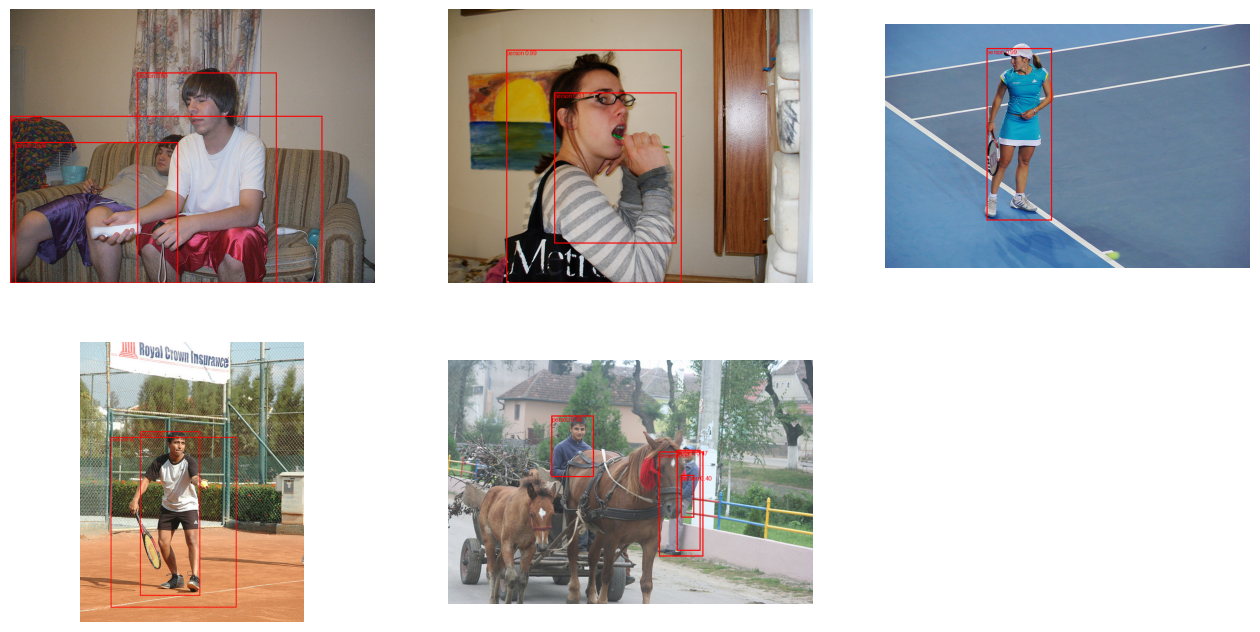

In [ ]:
# Mount Drive
from google.colab import drive
drive.mount("/content/drive")

# Imports
import torch, time, os, random
import torchvision
from torchvision import transforms
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
from tqdm import tqdm

# Dataset constants
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CLASSES = ["person","car","dog","cat","bicycle"]
CLASS2IDX = {c:i+1 for i,c in enumerate(CLASSES)}  # +1 because 0 is background
IDX2CLASS = {v:k for k,v in CLASS2IDX.items()}

# Custom Dataset wrapper for COCO via FiftyOne
class FasterRCNNDataset(Dataset):
    def __init__(self, fo_dataset, transforms=None):
        self.samples = list(fo_dataset)
        self.transforms = transforms

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        sample = self.samples[idx]
        img = Image.open(sample.filepath).convert("RGB")
        w,h = img.size

        # Build target dict
        boxes = []
        labels = []
        for det in sample.ground_truth.detections:
            label = det.label
            if label not in CLASS2IDX:
                continue
            x,y,wd,hd = det.bounding_box
            # COCO normalized → absolute
            xmin = x * w
            ymin = y * h
            xmax = xmin + wd * w
            ymax = ymin + hd * h
            boxes.append([xmin,ymin,xmax,ymax])
            labels.append(CLASS2IDX[label])

        boxes = torch.tensor(boxes, dtype=torch.float32)
        labels = torch.tensor(labels, dtype=torch.int64)

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([idx])
        }

        if self.transforms:
            img = self.transforms(img)

        return img, target

# Create dataset + loader
transform = transforms.Compose([transforms.ToTensor()])
train_dataset = FasterRCNNDataset(dataset, transforms=transform)
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, collate_fn=lambda x: tuple(zip(*x)))

# Create model: Faster R-CNN from torchvision
num_classes = len(CLASSES) + 1  # +1 for background
model = fasterrcnn_resnet50_fpn(weights=None, num_classes=num_classes).to(DEVICE)

# Optimizer
params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.Adam(params, lr=1e-4)

# Training
os.makedirs("/content/drive/MyDrive/YOLO_Project/fasterrcnn", exist_ok=True)
best_loss = float("inf")

for epoch in range(15):  # adjust epochs
    model.train()
    epoch_loss = 0
    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}")
    for imgs, targets in pbar:
        imgs = list(img.to(DEVICE) for img in imgs)
        tgt = [{k:v.to(DEVICE) for k,v in t.items()} for t in targets]

        loss_dict = model(imgs, tgt)
        loss = sum(loss for loss in loss_dict.values())

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        pbar.set_postfix(loss=loss.item())

    avg_loss = epoch_loss / len(train_loader)
    print(f"Epoch {epoch+1} | Avg Loss: {avg_loss:.4f}")

    # Save best model
    model_path = f"/content/drive/MyDrive/YOLO_Project/fasterrcnn/fasterrcnn_epoch{epoch+1}.pth"
    torch.save(model.state_dict(), model_path)

# Save final
final_path = "/content/drive/MyDrive/YOLO_Project/fasterrcnn/best_fasterrcnn.pth"
torch.save(model.state_dict(), final_path)
print(f"Models saved at /content/drive/MyDrive/YOLO_Project/fasterrcnn")

# Simple inference visualization
model.eval()
def draw_preds(img, preds):
    draw = ImageDraw.Draw(img)
    for box, label, score in zip(preds["boxes"], preds["labels"], preds["scores"]):
        if score < 0.3: continue
        x1,y1,x2,y2 = box
        draw.rectangle([x1,y1,x2,y2], outline="red", width=2)
        draw.text((x1,y1), f"{IDX2CLASS[int(label)]} {score:.2f}", fill="red")
    return img

# Display 5 random results
import random
fig=plt.figure(figsize=(16,8))
for i in range(5):
    idx = random.randrange(len(train_dataset))
    img, _ = train_dataset[idx]
    img_cpu = img.clone().cpu()
    with torch.no_grad():
        preds = model([img.to(DEVICE)])[0]
    pil = transforms.ToPILImage()(img_cpu)
    pil = draw_preds(pil, preds)
    ax = fig.add_subplot(2,3,i+1)
    ax.imshow(pil)
    ax.axis("off")
plt.show()


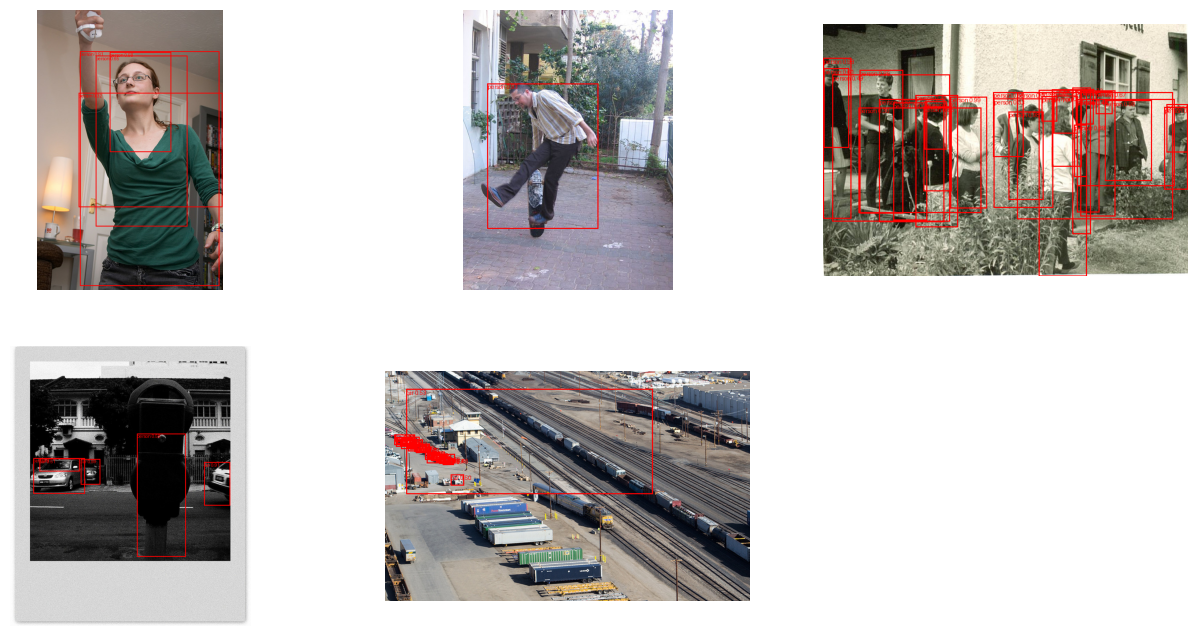

In [ ]:
# Display 5 random results
import random
fig=plt.figure(figsize=(16,8))
for i in range(5):
    idx = random.randrange(len(train_dataset))
    img, _ = train_dataset[idx]
    img_cpu = img.clone().cpu()
    with torch.no_grad():
        preds = model([img.to(DEVICE)])[0]
    pil = transforms.ToPILImage()(img_cpu)
    pil = draw_preds(pil, preds)
    ax = fig.add_subplot(2,3,i+1)
    ax.imshow(pil)
    ax.axis("off")
plt.show()

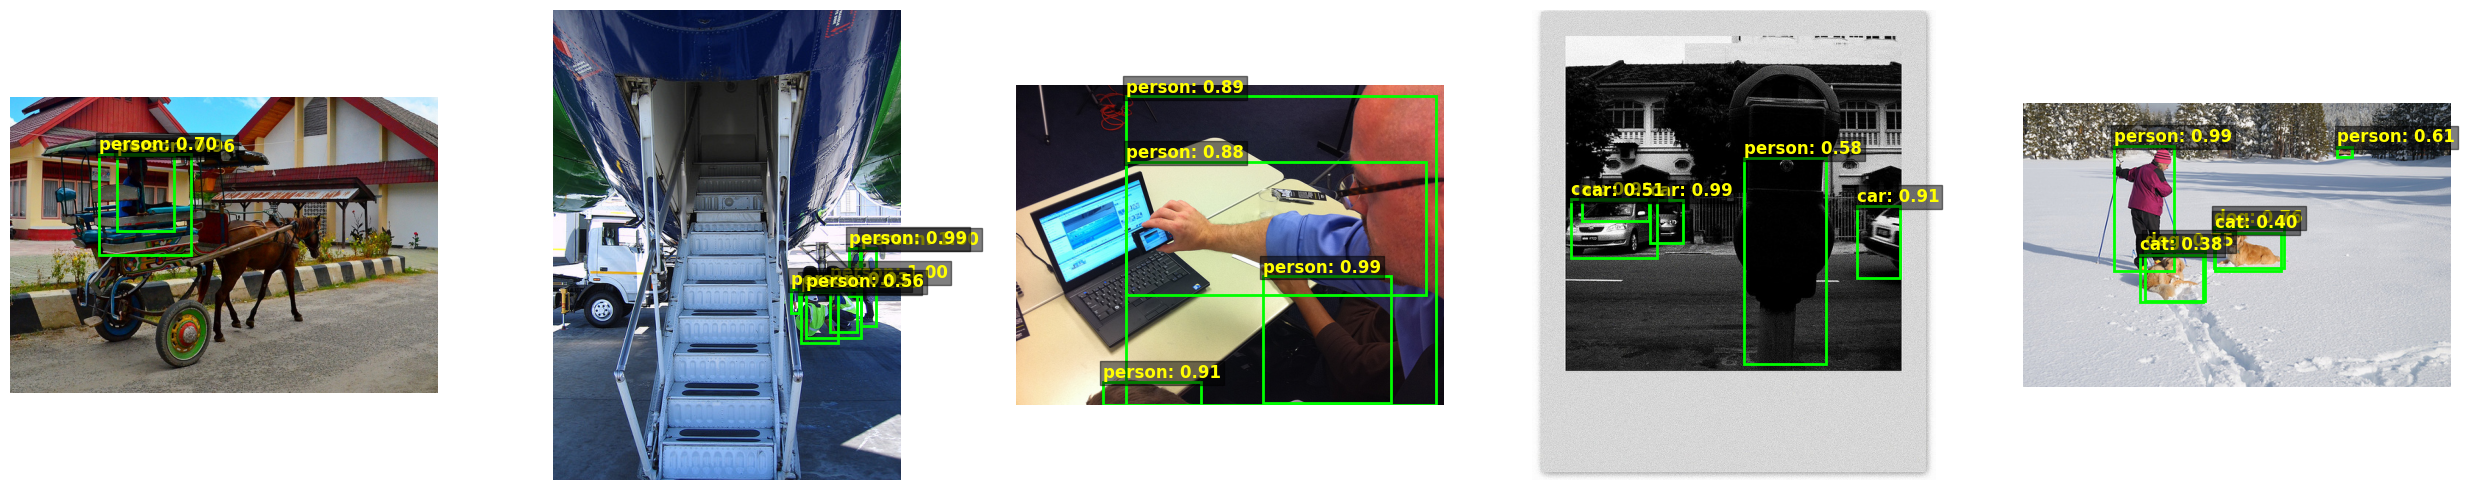

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def visualize_predictions(model, dataset, n=5, conf_thresh=0.3):
    """
    Display n random images from the dataset with predicted boxes.
    Boxes and labels are clearly visible using matplotlib.
    """
    model.eval()
    fig, axs = plt.subplots(1, n, figsize=(5*n,5))
    if n == 1: axs = [axs]

    for ax in axs:
        idx = random.randrange(len(dataset))
        img, _ = dataset[idx]
        img_tensor = img.unsqueeze(0).to(DEVICE)

        with torch.no_grad():
            preds = model(img_tensor)[0]

        # Convert image to numpy
        img_np = img.permute(1,2,0).cpu().numpy()
        ax.imshow(img_np)
        ax.axis("off")

        # Draw boxes
        for box, label, score in zip(preds["boxes"], preds["labels"], preds["scores"]):
            if score < conf_thresh:
                continue
            x1, y1, x2, y2 = box.cpu().numpy()
            rect = patches.Rectangle(
                (x1, y1), x2-x1, y2-y1,
                linewidth=2, edgecolor='lime', facecolor='none'
            )
            ax.add_patch(rect)
            ax.text(
                x1, y1-5, f"{IDX2CLASS[int(label)]}: {score:.2f}",
                color='yellow', fontsize=12, weight='bold',
                bbox=dict(facecolor='black', alpha=0.5, pad=2)
            )

    plt.tight_layout()
    plt.show()

# Usage: display 5 images with clearly visible bounding boxes
visualize_predictions(model, train_dataset, n=5, conf_thresh=0.3)


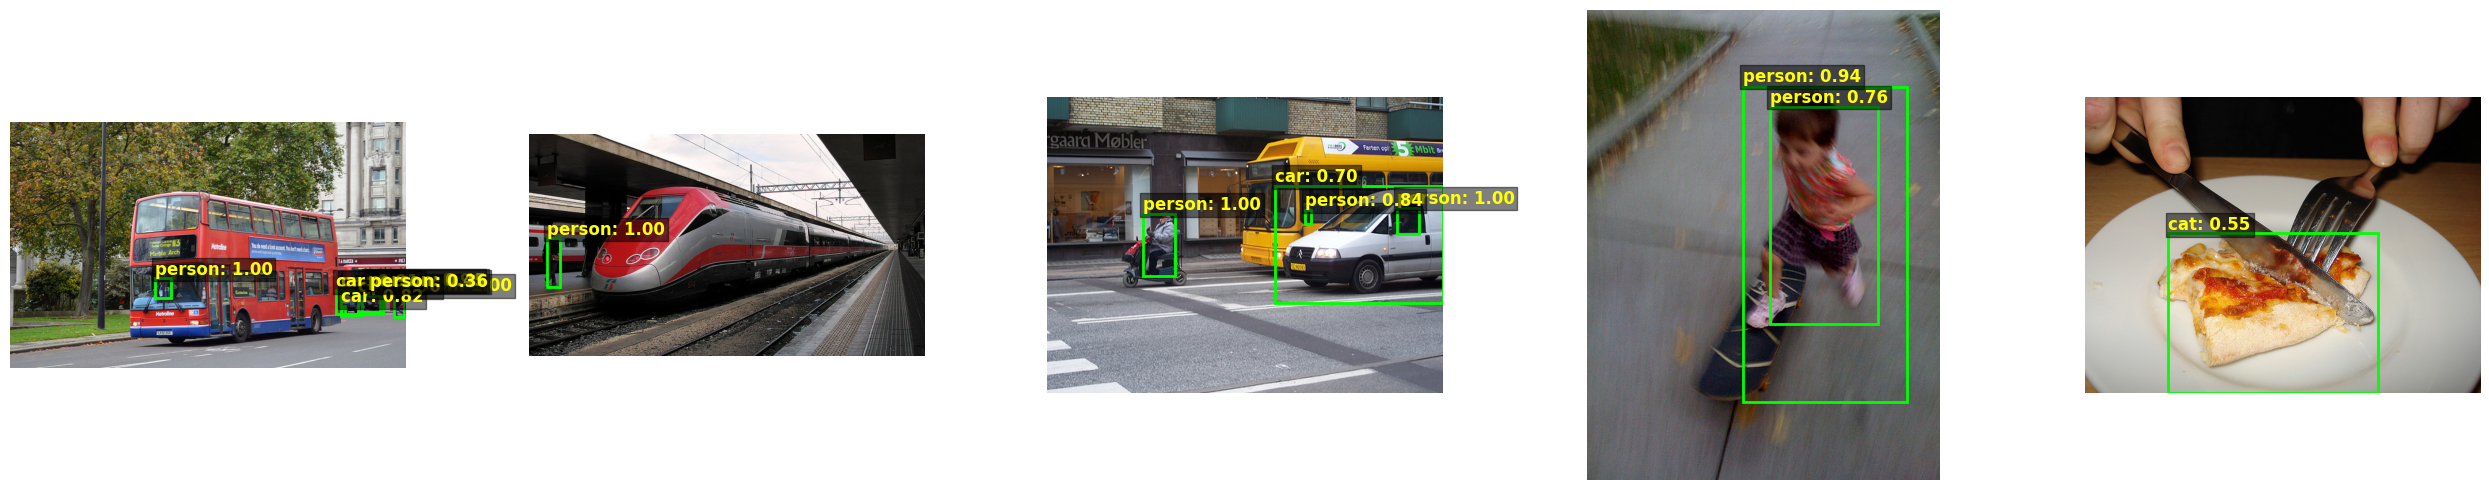

In [ ]:
# Usage: display 5 images with clearly visible bounding boxes
visualize_predictions(model, train_dataset, n=5, conf_thresh=0.3)

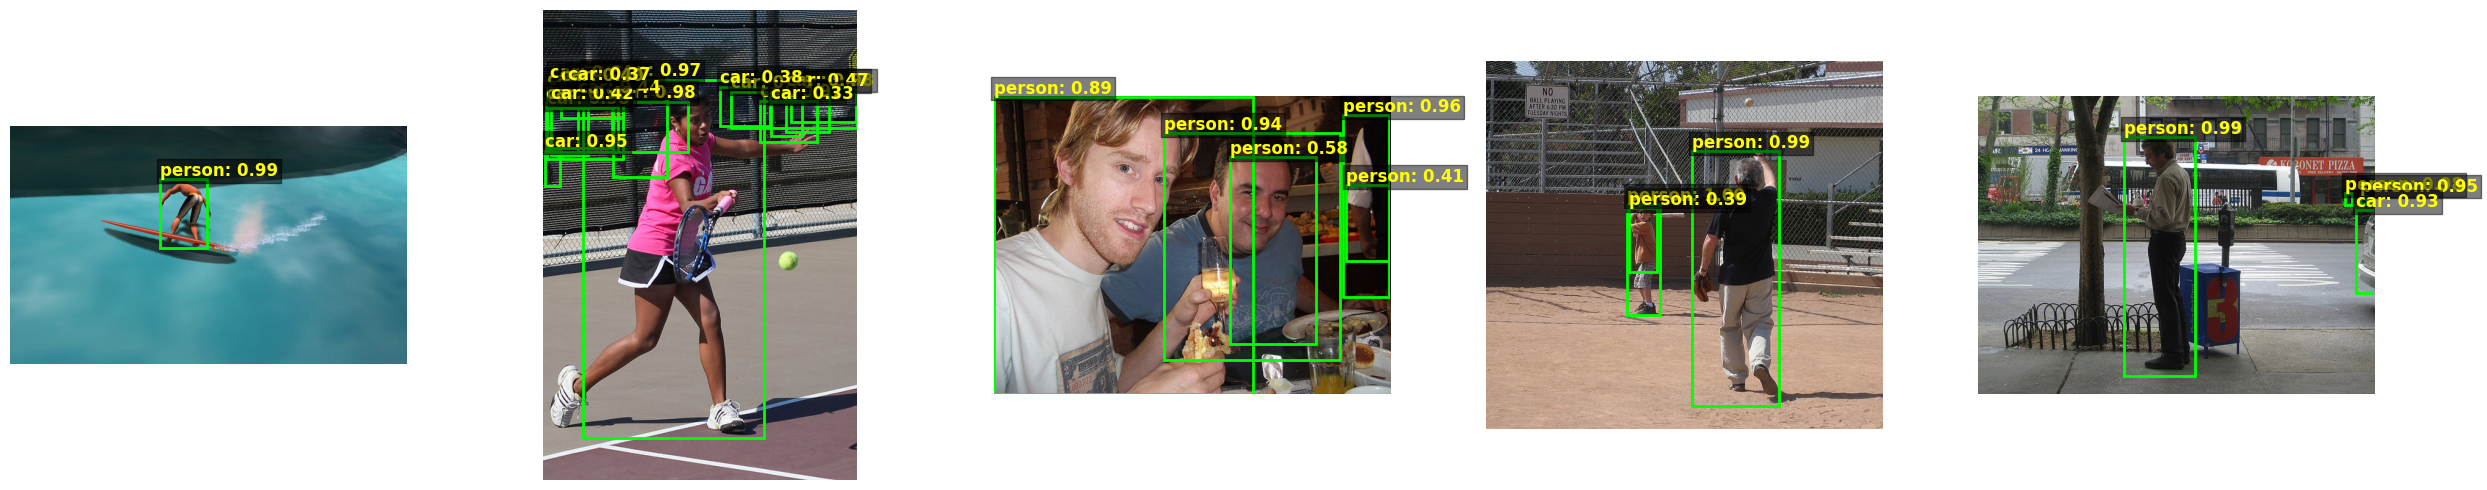

In [ ]:
# Usage: display 5 images with clearly visible bounding boxes
visualize_predictions(model, train_dataset, n=5, conf_thresh=0.3)

In [ ]:
# so far we saw person , car, bicycle, cat and dogs which is exhaustive for the classes the model was trained for

In [ ]:
from google.colab import drive
import os
import torch
import fiftyone as fo

# Mount GDrive
drive.mount("/content/drive")

# Create folder "final"
save_dir = "/content/drive/MyDrive/final"
os.makedirs(save_dir, exist_ok=True)

# ---------- 1. Save the 500-sample dataset ----------
dataset_name = "coco_yolo_subset"  # your FiftyOne dataset
dataset = fo.load_dataset(dataset_name)
dataset.save()  # ensures persistence
dataset_dir = os.path.join(save_dir, "dataset")
dataset.export(
    export_dir=dataset_dir,
    dataset_type=fo.types.FiftyOneDataset,
)
print(f"Dataset saved to: {dataset_dir}")

# ---------- 2. Save the trained Faster R-CNN model ----------
model_path = os.path.join(save_dir, "best_fasterrcnn.pth")
torch.save(model.state_dict(), model_path)
print(f"Model saved to: {model_path}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Exporting samples...


INFO:fiftyone.utils.data.exporters:Exporting samples...


 100% |████████████████████| 500/500 [5.4s elapsed, 0s remaining, 84.9 docs/s]       


INFO:eta.core.utils: 100% |████████████████████| 500/500 [5.4s elapsed, 0s remaining, 84.9 docs/s]       


Dataset saved to: /content/drive/MyDrive/final/dataset
Model saved to: /content/drive/MyDrive/final/best_fasterrcnn.pth


In [ ]:
import torch, time, os
import torchvision
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.ops import box_iou
import numpy as np
from tqdm import tqdm

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CONF_THRESH = 0.3

# ---------- 1. Model size ----------
model_path = "/content/drive/MyDrive/final/best_fasterrcnn.pth"
model = fasterrcnn_resnet50_fpn(weights=None, num_classes=len(CLASSES)+1).to(DEVICE)
model.load_state_dict(torch.load(model_path, map_location=DEVICE))
model.eval()
model_size_mb = os.path.getsize(model_path)/1e6
print(f"Model size: {model_size_mb:.2f} MB")

# ---------- 2. Inference FPS ----------
dummy = torch.randn(1,3,IMG_SIZE,IMG_SIZE).to(DEVICE)
with torch.no_grad():
    start = time.time()
    for _ in range(50):
        _ = model(dummy)
fps = 50/(time.time()-start)
print(f"Inference FPS: {fps:.2f}")

# ---------- 3. mAP calculation ----------
def compute_map(model, dataset, iou_thresh=0.5):
    """
    Computes mAP @ IoU=0.5 for the dataset
    """
    all_scores = []
    all_matches = []

    for img, target in tqdm(dataset, desc="Evaluating"):
        img = img.unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            preds = model(img)[0]

        gt_boxes = target["boxes"].to(DEVICE)
        gt_labels = target["labels"].to(DEVICE)
        pred_boxes = preds["boxes"].to(DEVICE)
        pred_labels = preds["labels"].to(DEVICE)
        pred_scores = preds["scores"].to(DEVICE)

        for cls_id in range(1, len(CLASSES)+1):
            # GT for this class
            gt_cls_boxes = gt_boxes[gt_labels==cls_id]
            pred_cls_mask = pred_labels==cls_id
            pred_cls_boxes = pred_boxes[pred_cls_mask]
            pred_cls_scores = pred_scores[pred_cls_mask]

            if len(pred_cls_boxes)==0:
                continue

            # Sort by confidence
            sort_idx = torch.argsort(pred_cls_scores, descending=True)
            pred_cls_boxes = pred_cls_boxes[sort_idx]
            pred_cls_scores = pred_cls_scores[sort_idx]

            matched = torch.zeros(len(gt_cls_boxes), device=DEVICE)
            tp = torch.zeros(len(pred_cls_boxes), device=DEVICE)
            fp = torch.zeros(len(pred_cls_boxes), device=DEVICE)

            for i, pb in enumerate(pred_cls_boxes):
                if len(gt_cls_boxes)==0:
                    fp[i] = 1
                    continue
                ious = box_iou(pb.unsqueeze(0), gt_cls_boxes).squeeze(0)
                max_iou, idx = ious.max(0)
                if max_iou>iou_thresh and matched[idx]==0:
                    tp[i] = 1
                    matched[idx] = 1
                else:
                    fp[i] = 1

            # Precision/recall
            tp_cum = torch.cumsum(tp, dim=0)
            fp_cum = torch.cumsum(fp, dim=0)
            precisions = tp_cum / (tp_cum+fp_cum+1e-6)
            recalls = tp_cum / (len(gt_cls_boxes)+1e-6)

            # AP = area under PR curve
            precisions = torch.cat([torch.tensor([1.0], device=DEVICE), precisions, torch.tensor([0.0], device=DEVICE)])
            recalls = torch.cat([torch.tensor([0.0], device=DEVICE), recalls, torch.tensor([1.0], device=DEVICE)])
            for i in range(len(precisions)-1,0,-1):
                precisions[i-1] = torch.max(precisions[i-1], precisions[i])
            indices = torch.where(recalls[1:]!=recalls[:-1])[0]
            ap = torch.sum((recalls[indices+1]-recalls[indices])*precisions[indices+1])
            all_scores.append(ap.item())

    mean_ap = np.mean(all_scores)
    return mean_ap

# Convert your train_dataset to FasterRCNNDataset format
eval_map = compute_map(model, train_dataset)
print(f"mAP @ IoU=0.5: {eval_map:.4f}")


Model size: 165.81 MB
Inference FPS: 11.30


Evaluating: 100%|██████████| 500/500 [01:18<00:00,  6.39it/s]

mAP @ IoU=0.5: 0.0028
